In [1]:
# Mount Google Drive
from google.colab import drive
drive.mount('/content/drive')

print("✅ Google Drive mounted successfully!")

Mounted at /content/drive
✅ Google Drive mounted successfully!


In [2]:
# ============================================================================
# NOTEBOOK 2: MODELING
# Healthcare Provider Fraud Detection
# ============================================================================

print("="*70)
print("🤖 NOTEBOOK 2: MODELING")
print("="*70)

# Import necessary libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import (
    classification_report, confusion_matrix, accuracy_score,
    roc_auc_score, roc_curve, precision_recall_curve,
    f1_score, precision_score, recall_score, auc,
    average_precision_score
)
from sklearn.tree import DecisionTreeClassifier # Added missing import
from xgboost import XGBClassifier # Added missing import
from sklearn.svm import SVC # Added missing import

from imblearn.over_sampling import SMOTE
from imblearn.under_sampling import RandomUnderSampler
from imblearn.combine import SMOTETomek
import warnings
warnings.filterwarnings('ignore')

# Set visualization style
sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (12, 6)

print("\n✓ All libraries imported successfully!")
print("="*70)

🤖 NOTEBOOK 2: MODELING

✓ All libraries imported successfully!


In [3]:
# ============================================================================
# SECTION 1: LOAD PROCESSED DATA
# ============================================================================

print("\n📂 LOADING PROCESSED DATA FROM NOTEBOOK 1")
print("="*70)

# Load the final processed dataset
df = pd.read_csv('/content/drive/MyDrive/fraud_detection_project/data/processed_data.csv')

print(f"\n✅ Dataset loaded successfully!")
print(f"📊 Shape: {df.shape}")
print(f"👥 Total Providers: {len(df):,}")
print(f"🎯 Features: {df.shape[1]}")

# Check target distribution
print(f"\n🎯 TARGET DISTRIBUTION:")
print("-"*70)
fraud_counts = df['PotentialFraud'].value_counts()
print(f"   Legitimate (0): {fraud_counts[0]:,} ({fraud_counts[0]/len(df)*100:.2f}%)")
print(f"   Fraudulent (1): {fraud_counts[1]:,} ({fraud_counts[1]/len(df)*100:.2f}%)")
print(f"   Imbalance Ratio: {fraud_counts[0]/fraud_counts[1]:.2f}:1")

# Check for missing values
print(f"\n🔍 DATA QUALITY:")
print("-"*70)
missing = df.isnull().sum().sum()
print(f"   Missing values: {missing}")
print(f"   Data types: {df.dtypes.value_counts().to_dict()}")

print("="*70)


📂 LOADING PROCESSED DATA FROM NOTEBOOK 1

✅ Dataset loaded successfully!
📊 Shape: (5410, 51)
👥 Total Providers: 5,410
🎯 Features: 51

🎯 TARGET DISTRIBUTION:
----------------------------------------------------------------------
   Legitimate (0): 4,904 (90.65%)
   Fraudulent (1): 506 (9.35%)
   Imbalance Ratio: 9.69:1

🔍 DATA QUALITY:
----------------------------------------------------------------------
   Missing values: 0
   Data types: {dtype('float64'): 31, dtype('int64'): 19, dtype('O'): 1}


In [4]:
# Load the processed data we created in Notebook 1
print("="*70)
print("LOADING PROCESSED DATA")
print("="*70)

data_path = '/content/drive/MyDrive/fraud_detection_project/data/processed_data.csv'

print(f"\nLoading from: {data_path}")
data = pd.read_csv(data_path)

print(f"✅ Data loaded successfully!")
print(f"\nDataset shape: {data.shape}")
print(f"  • Providers: {data.shape[0]:,}")
print(f"  • Features: {data.shape[1]}")

print("\n" + "="*70)
print("First 5 rows:")
print(data.head())

print("\n" + "="*70)
print("Target variable distribution:")
print(data['PotentialFraud'].value_counts())
print("\nPercentages:")
print(data['PotentialFraud'].value_counts(normalize=True) * 100)

LOADING PROCESSED DATA

Loading from: /content/drive/MyDrive/fraud_detection_project/data/processed_data.csv
✅ Data loaded successfully!

Dataset shape: (5410, 51)
  • Providers: 5,410
  • Features: 51

First 5 rows:
   Provider  PotentialFraud  num_beneficiaries  num_deceased  num_male  \
0  PRV51001               0                 24             0         9   
1  PRV51003               1                117             1        49   
2  PRV51004               0                138             1        45   
3  PRV51005               1                495             3       208   
4  PRV51007               0                 58             1        27   

   most_common_race  num_renal_disease  num_alzheimer  num_heartfailure  \
0                 1                  8             14                18   
1                 1                 22             44                70   
2                 1                 20             60                82   
3                 1                 79

In [5]:
# Verify the link between notebooks
import os

print("CHECKING CONNECTION TO NOTEBOOK 1")
print("="*70)

# Check if processed data exists
processed_file = '/content/drive/MyDrive/fraud_detection_project/data/processed_data.csv'

if os.path.exists(processed_file):
    print("✅ SUCCESS! Notebook 2 is connected to Notebook 1")
    print(f"✅ Found: processed_data.csv")

    # Load and verify
    import pandas as pd
    data = pd.read_csv(processed_file)
    print(f"\n✅ Data loaded: {data.shape[0]:,} providers × {data.shape[1]} features")
    print(f"✅ Target variable exists: {'PotentialFraud' in data.columns}")
    print("\n🎉 NOTEBOOKS ARE LINKED! You can proceed!")
else:
    print("❌ ERROR: Cannot find processed_data.csv")
    print("❌ Go back to Notebook 1 and run Step 32 to save the data!")

CHECKING CONNECTION TO NOTEBOOK 1
✅ SUCCESS! Notebook 2 is connected to Notebook 1
✅ Found: processed_data.csv

✅ Data loaded: 5,410 providers × 51 features
✅ Target variable exists: True

🎉 NOTEBOOKS ARE LINKED! You can proceed!


In [6]:
# Separate features (X) and target (y)
print("="*70)
print("PREPARING DATA FOR MODELING")
print("="*70)

# Remove ID and target columns
X = data.drop(['Provider', 'PotentialFraud'], axis=1)
y = data['PotentialFraud']

print(f"\n✅ Data separated!")
print(f"\nFeatures (X): {X.shape}")
print(f"  • Number of features: {X.shape[1]}")
print(f"\nTarget (y): {y.shape}")
print(f"  • Fraud: {y.sum():,} ({y.sum()/len(y)*100:.1f}%)")
print(f"  • Non-fraud: {(y==0).sum():,} ({(y==0).sum()/len(y)*100:.1f}%)")

print("\nFeature names (first 10):")
for i, col in enumerate(X.columns[:10], 1):
    print(f"  {i}. {col}")
print(f"  ... and {X.shape[1]-10} more features")

PREPARING DATA FOR MODELING

✅ Data separated!

Features (X): (5410, 49)
  • Number of features: 49

Target (y): (5410,)
  • Fraud: 506 (9.4%)
  • Non-fraud: 4,904 (90.6%)

Feature names (first 10):
  1. num_beneficiaries
  2. num_deceased
  3. num_male
  4. most_common_race
  5. num_renal_disease
  6. num_alzheimer
  7. num_heartfailure
  8. num_kidney
  9. num_cancer
  10. num_obstr_pulmonary
  ... and 39 more features


In [7]:
# Split into training and testing sets
print("="*70)
print("TRAIN-TEST SPLIT")
print("="*70)

# 80% train, 20% test, stratified
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y  # Keeps fraud ratio same in both sets
)

print(f"\n✅ Data split complete!")

print(f"\nTRAINING SET: {X_train.shape[0]:,} samples")
print(f"  • Fraud: {y_train.sum():,} ({y_train.sum()/len(y_train)*100:.1f}%)")
print(f"  • Non-fraud: {(y_train==0).sum():,} ({(y_train==0).sum()/len(y_train)*100:.1f}%)")

print(f"\nTEST SET: {X_test.shape[0]:,} samples")
print(f"  • Fraud: {y_test.sum():,} ({y_test.sum()/len(y_test)*100:.1f}%)")
print(f"  • Non-fraud: {(y_test==0).sum():,} ({(y_test==0).sum()/len(y_test)*100:.1f}%)")

TRAIN-TEST SPLIT

✅ Data split complete!

TRAINING SET: 4,328 samples
  • Fraud: 405 (9.4%)
  • Non-fraud: 3,923 (90.6%)

TEST SET: 1,082 samples
  • Fraud: 101 (9.3%)
  • Non-fraud: 981 (90.7%)


In [8]:
# Scale features to same range
print("="*70)
print("FEATURE SCALING")
print("="*70)

scaler = StandardScaler()

# Fit on training, transform both
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(f"\n✅ Features scaled!")
print(f"\nBefore scaling (sample feature):")
print(f"  • Mean: {X_train.iloc[:, 0].mean():.2f}")
print(f"  • Std: {X_train.iloc[:, 0].std():.2f}")

print(f"\nAfter scaling (sample feature):")
print(f"  • Mean: {X_train_scaled[:, 0].mean():.2f}")
print(f"  • Std: {X_train_scaled[:, 0].std():.2f}")

FEATURE SCALING

✅ Features scaled!

Before scaling (sample feature):
  • Mean: 64.48
  • Std: 133.55

After scaling (sample feature):
  • Mean: 0.00
  • Std: 1.00


In [9]:
# Balance training data with SMOTE
from collections import Counter # Import Counter

print("="*70)
print("APPLYING SMOTE TO BALANCE TRAINING DATA")
print("="*70)

print(f"\nBEFORE SMOTE:")
print(f"  Distribution: {Counter(y_train)}")
print(f"  Imbalance ratio: {(y_train==0).sum() / y_train.sum():.1f}:1")

# Apply SMOTE
smote = SMOTE(random_state=42)
X_train_balanced, y_train_balanced = smote.fit_resample(X_train_scaled, y_train)

print(f"\nAFTER SMOTE:")
print(f"  Distribution: {Counter(y_train_balanced)}")
print(f"  Ratio: 1:1 (balanced!)")

print(f"\n✅ Training data balanced!")
print(f"  Original size: {len(y_train):,}")
print(f"  New size: {len(y_train_balanced):,}")
print(f"  Synthetic fraud cases created: {y_train_balanced.sum() - y_train.sum():,}")

APPLYING SMOTE TO BALANCE TRAINING DATA

BEFORE SMOTE:
  Distribution: Counter({0: 3923, 1: 405})
  Imbalance ratio: 9.7:1

AFTER SMOTE:
  Distribution: Counter({0: 3923, 1: 3923})
  Ratio: 1:1 (balanced!)

✅ Training data balanced!
  Original size: 4,328
  New size: 7,846
  Synthetic fraud cases created: 3,518


In [10]:
# =============================================================================
# TRAIN ALL 5 MODELS
# =============================================================================

print("="*80)
print("🚀 TRAINING 5 MACHINE LEARNING MODELS")
print("="*80)

# Storage
results = {}
predictions = {}
probabilities = {}
confusion_matrices = {}
models = {}

# -----------------------------------------------------------------------------
# MODEL 1: LOGISTIC REGRESSION
# -----------------------------------------------------------------------------

print("\n[1/5] Training Logistic Regression...")

lr = LogisticRegression(random_state=42, max_iter=1000, class_weight='balanced')
lr.fit(X_train_balanced, y_train_balanced)

y_pred_lr = lr.predict(X_test_scaled)
y_prob_lr = lr.predict_proba(X_test_scaled)[:, 1]

models['Logistic Regression'] = lr
predictions['Logistic Regression'] = y_pred_lr
probabilities['Logistic Regression'] = y_prob_lr
confusion_matrices['Logistic Regression'] = confusion_matrix(y_test, y_pred_lr)
results['Logistic Regression'] = {
    'Accuracy': accuracy_score(y_test, y_pred_lr),
    'Precision': precision_score(y_test, y_pred_lr),
    'Recall': recall_score(y_test, y_pred_lr),
    'F1-Score': f1_score(y_test, y_pred_lr),
    'ROC-AUC': roc_auc_score(y_test, y_prob_lr)
}
print(f"✅ Logistic Regression - ROC-AUC: {results['Logistic Regression']['ROC-AUC']:.4f}")

# -----------------------------------------------------------------------------
# MODEL 2: DECISION TREE
# -----------------------------------------------------------------------------

print("\n[2/5] Training Decision Tree...")

dt = DecisionTreeClassifier(max_depth=10, min_samples_split=20, random_state=42, class_weight='balanced')
dt.fit(X_train_balanced, y_train_balanced)

y_pred_dt = dt.predict(X_test_scaled)
y_prob_dt = dt.predict_proba(X_test_scaled)[:, 1]

models['Decision Tree'] = dt
predictions['Decision Tree'] = y_pred_dt
probabilities['Decision Tree'] = y_prob_dt
confusion_matrices['Decision Tree'] = confusion_matrix(y_test, y_pred_dt)
results['Decision Tree'] = {
    'Accuracy': accuracy_score(y_test, y_pred_dt),
    'Precision': precision_score(y_test, y_pred_dt),
    'Recall': recall_score(y_test, y_pred_dt),
    'F1-Score': f1_score(y_test, y_pred_dt),
    'ROC-AUC': roc_auc_score(y_test, y_prob_dt)
}
print(f"✅ Decision Tree - ROC-AUC: {results['Decision Tree']['ROC-AUC']:.4f}")

# -----------------------------------------------------------------------------
# MODEL 3: RANDOM FOREST
# -----------------------------------------------------------------------------

print("\n[3/5] Training Random Forest (may take 1-2 min)...")

rf = RandomForestClassifier(n_estimators=100, max_depth=15, random_state=42, n_jobs=-1, class_weight='balanced')
rf.fit(X_train_balanced, y_train_balanced)

y_pred_rf = rf.predict(X_test_scaled)
y_prob_rf = rf.predict_proba(X_test_scaled)[:, 1]

models['Random Forest'] = rf
predictions['Random Forest'] = y_pred_rf
probabilities['Random Forest'] = y_prob_rf
confusion_matrices['Random Forest'] = confusion_matrix(y_test, y_pred_rf)
results['Random Forest'] = {
    'Accuracy': accuracy_score(y_test, y_pred_rf),
    'Precision': precision_score(y_test, y_pred_rf),
    'Recall': recall_score(y_test, y_pred_rf),
    'F1-Score': f1_score(y_test, y_pred_rf),
    'ROC-AUC': roc_auc_score(y_test, y_prob_rf)
}
print(f"✅ Random Forest - ROC-AUC: {results['Random Forest']['ROC-AUC']:.4f}")

# -----------------------------------------------------------------------------
# MODEL 4: XGBOOST (GRADIENT BOOSTING)
# -----------------------------------------------------------------------------

print("\n[4/5] Training XGBoost...")

xgb = XGBClassifier(n_estimators=100, max_depth=6, learning_rate=0.1, random_state=42, n_jobs=-1, eval_metric='logloss')
xgb.fit(X_train_balanced, y_train_balanced)

y_pred_xgb = xgb.predict(X_test_scaled)
y_prob_xgb = xgb.predict_proba(X_test_scaled)[:, 1]

models['XGBoost'] = xgb
predictions['XGBoost'] = y_pred_xgb
probabilities['XGBoost'] = y_prob_xgb
confusion_matrices['XGBoost'] = confusion_matrix(y_test, y_pred_xgb)
results['XGBoost'] = {
    'Accuracy': accuracy_score(y_test, y_pred_xgb),
    'Precision': precision_score(y_test, y_pred_xgb),
    'Recall': recall_score(y_test, y_pred_xgb),
    'F1-Score': f1_score(y_test, y_pred_xgb),
    'ROC-AUC': roc_auc_score(y_test, y_prob_xgb)
}
print(f"✅ XGBoost - ROC-AUC: {results['XGBoost']['ROC-AUC']:.4f}")

# -----------------------------------------------------------------------------
# MODEL 5: SVM
# -----------------------------------------------------------------------------

print("\n[5/5] Training SVM (may take 2-3 min)...")

svm = SVC(kernel='rbf', C=1.0, random_state=42, class_weight='balanced', probability=True)
svm.fit(X_train_balanced, y_train_balanced)

y_pred_svm = svm.predict(X_test_scaled)
y_prob_svm = svm.predict_proba(X_test_scaled)[:, 1]

models['SVM'] = svm
predictions['SVM'] = y_pred_svm
probabilities['SVM'] = y_prob_svm
confusion_matrices['SVM'] = confusion_matrix(y_test, y_pred_svm)
results['SVM'] = {
    'Accuracy': accuracy_score(y_test, y_pred_svm),
    'Precision': precision_score(y_test, y_pred_svm),
    'Recall': recall_score(y_test, y_pred_svm),
    'F1-Score': f1_score(y_test, y_pred_svm),
    'ROC-AUC': roc_auc_score(y_test, y_prob_svm)
}
print(f"✅ SVM - ROC-AUC: {results['SVM']['ROC-AUC']:.4f}")

# =============================================================================
# SUMMARY
# =============================================================================

print("\n" + "="*80)
print("🏆 ALL 5 MODELS TRAINED!")
print("="*80)

comparison = pd.DataFrame(results).T
print("\n" + comparison.to_string())

best = comparison['ROC-AUC'].idxmax()
print(f"\n🥇 BEST MODEL: {best}")
print(f"   ROC-AUC: {comparison.loc[best, 'ROC-AUC']:.4f}")

# Save
comparison.to_csv('/content/drive/MyDrive/fraud_detection_project/results/model_comparison.csv')
print("\n✅ Results saved!")

🚀 TRAINING 5 MACHINE LEARNING MODELS

[1/5] Training Logistic Regression...
✅ Logistic Regression - ROC-AUC: 0.9506

[2/5] Training Decision Tree...
✅ Decision Tree - ROC-AUC: 0.9023

[3/5] Training Random Forest (may take 1-2 min)...
✅ Random Forest - ROC-AUC: 0.9492

[4/5] Training XGBoost...
✅ XGBoost - ROC-AUC: 0.9501

[5/5] Training SVM (may take 2-3 min)...
✅ SVM - ROC-AUC: 0.9399

🏆 ALL 5 MODELS TRAINED!

                     Accuracy  Precision    Recall  F1-Score   ROC-AUC
Logistic Regression  0.878928   0.427885  0.881188  0.576052  0.950586
Decision Tree        0.875231   0.409574  0.762376  0.532872  0.902282
Random Forest        0.916821   0.538462  0.762376  0.631148  0.949233
XGBoost              0.924214   0.574803  0.722772  0.640351  0.950091
SVM                  0.863216   0.397380  0.900990  0.551515  0.939877

🥇 BEST MODEL: Logistic Regression
   ROC-AUC: 0.9506

✅ Results saved!


Creating visualizations...


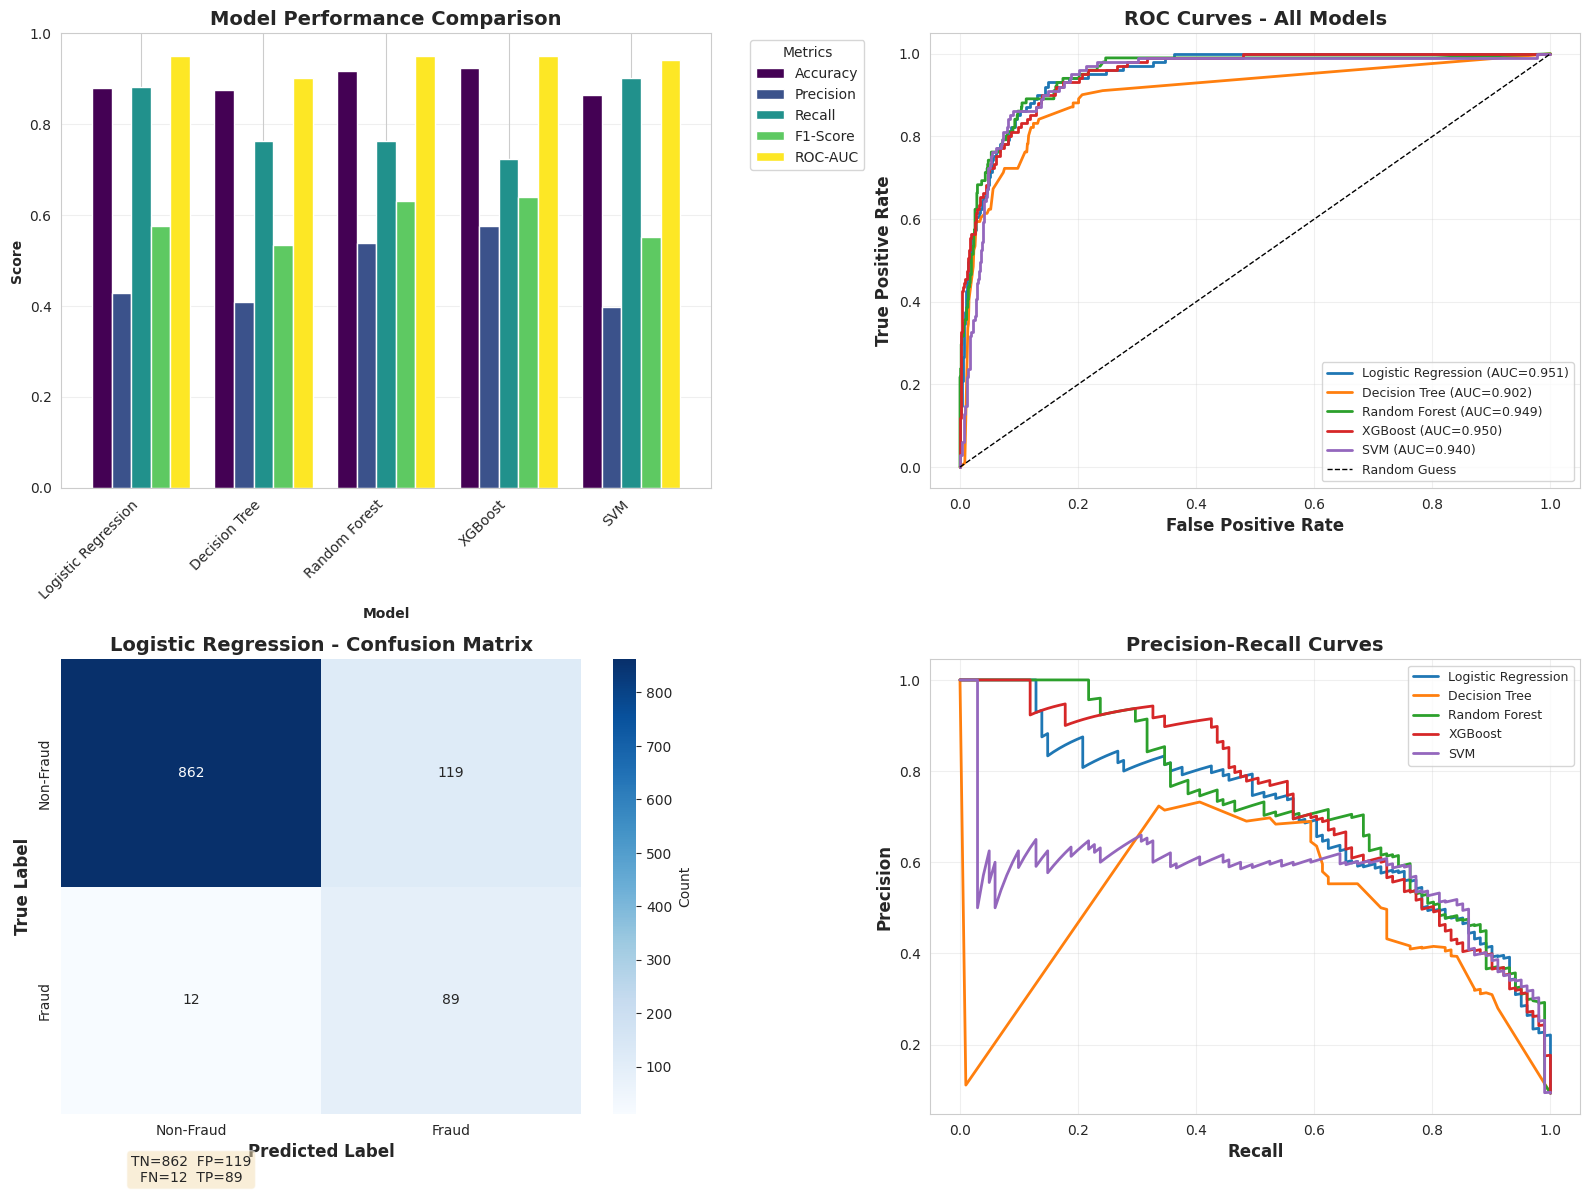

✅ Visualizations created and saved!


In [11]:
# Create comprehensive visualizations
print("Creating visualizations...")

fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# 1. Model Comparison Bar Chart
ax = axes[0, 0]
comparison.plot(kind='bar', ax=ax, width=0.8, colormap='viridis')
ax.set_title('Model Performance Comparison', fontsize=14, fontweight='bold')
ax.set_ylabel('Score', fontweight='bold')
ax.set_xlabel('Model', fontweight='bold')
ax.legend(title='Metrics', bbox_to_anchor=(1.05, 1), loc='upper left')
ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha='right')
ax.grid(axis='y', alpha=0.3)
ax.set_ylim(0, 1)

# 2. ROC Curves
ax = axes[0, 1]
for model_name in ['Logistic Regression', 'Decision Tree', 'Random Forest', 'XGBoost', 'SVM']:
    fpr, tpr, _ = roc_curve(y_test, probabilities[model_name])
    auc = results[model_name]['ROC-AUC']
    ax.plot(fpr, tpr, label=f'{model_name} (AUC={auc:.3f})', linewidth=2)

ax.plot([0, 1], [0, 1], 'k--', label='Random Guess', linewidth=1)
ax.set_xlabel('False Positive Rate', fontweight='bold', fontsize=12)
ax.set_ylabel('True Positive Rate', fontweight='bold', fontsize=12)
ax.set_title('ROC Curves - All Models', fontweight='bold', fontsize=14)
ax.legend(loc='lower right', fontsize=9)
ax.grid(alpha=0.3)

# 3. Confusion Matrix - Best Model
ax = axes[1, 0]
cm = confusion_matrices['Logistic Regression']
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax,
            xticklabels=['Non-Fraud', 'Fraud'],
            yticklabels=['Non-Fraud', 'Fraud'],
            cbar_kws={'label': 'Count'})
ax.set_title('Logistic Regression - Confusion Matrix', fontweight='bold', fontsize=14)
ax.set_ylabel('True Label', fontweight='bold', fontsize=12)
ax.set_xlabel('Predicted Label', fontweight='bold', fontsize=12)

# Add text annotations
tn, fp, fn, tp = cm.ravel()
ax.text(0.5, 2.3, f'TN={tn}  FP={fp}\nFN={fn}  TP={tp}',
        ha='center', fontsize=10, bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.5))

# 4. Precision-Recall Curves
ax = axes[1, 1]
for model_name in ['Logistic Regression', 'Decision Tree', 'Random Forest', 'XGBoost', 'SVM']:
    precision, recall, _ = precision_recall_curve(y_test, probabilities[model_name])
    ax.plot(recall, precision, label=model_name, linewidth=2)

ax.set_xlabel('Recall', fontweight='bold', fontsize=12)
ax.set_ylabel('Precision', fontweight='bold', fontsize=12)
ax.set_title('Precision-Recall Curves', fontweight='bold', fontsize=14)
ax.legend(loc='best', fontsize=9)
ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig('/content/drive/MyDrive/fraud_detection_project/results/all_models_evaluation.png',
            dpi=300, bbox_inches='tight')
plt.show()

print("✅ Visualizations created and saved!")

In [12]:
# Print detailed classification reports for all models
print("="*80)
print("📊 DETAILED CLASSIFICATION REPORTS")
print("="*80)

for model_name in ['Logistic Regression', 'Decision Tree', 'Random Forest', 'XGBoost', 'SVM']:
    print(f"\n{'='*80}")
    print(f"{model_name.upper()}")
    print('='*80)
    print("\nClassification Report:")
    print(classification_report(y_test, predictions[model_name],
                                target_names=['Non-Fraud (0)', 'Fraud (1)'],
                                digits=4))

    print("\nConfusion Matrix:")
    cm = confusion_matrices[model_name]
    print(cm)

    tn, fp, fn, tp = cm.ravel()
    print(f"\nBreakdown:")
    print(f"  True Negatives (Correct Non-Fraud):  {tn:4d}")
    print(f"  False Positives (Wrong - Flag Legit): {fp:4d}")
    print(f"  False Negatives (Wrong - Miss Fraud): {fn:4d}")
    print(f"  True Positives (Correct Fraud):       {tp:4d}")

    print(f"\nKey Metrics:")
    print(f"  ROC-AUC:   {results[model_name]['ROC-AUC']:.4f}")
    print(f"  Precision: {results[model_name]['Precision']:.4f}")
    print(f"  Recall:    {results[model_name]['Recall']:.4f}")
    print(f"  F1-Score:  {results[model_name]['F1-Score']:.4f}")

📊 DETAILED CLASSIFICATION REPORTS

LOGISTIC REGRESSION

Classification Report:
               precision    recall  f1-score   support

Non-Fraud (0)     0.9863    0.8787    0.9294       981
    Fraud (1)     0.4279    0.8812    0.5761       101

     accuracy                         0.8789      1082
    macro avg     0.7071    0.8799    0.7527      1082
 weighted avg     0.9341    0.8789    0.8964      1082


Confusion Matrix:
[[862 119]
 [ 12  89]]

Breakdown:
  True Negatives (Correct Non-Fraud):   862
  False Positives (Wrong - Flag Legit):  119
  False Negatives (Wrong - Miss Fraud):   12
  True Positives (Correct Fraud):         89

Key Metrics:
  ROC-AUC:   0.9506
  Precision: 0.4279
  Recall:    0.8812
  F1-Score:  0.5761

DECISION TREE

Classification Report:
               precision    recall  f1-score   support

Non-Fraud (0)     0.9732    0.8869    0.9280       981
    Fraud (1)     0.4096    0.7624    0.5329       101

     accuracy                         0.8752      1082


In [13]:
# Error Analysis for Best Model
print("="*80)
print("🔍 ERROR ANALYSIS - LOGISTIC REGRESSION (BEST MODEL)")
print("="*80)

best_model_name = 'Logistic Regression'
y_pred_best = predictions[best_model_name]

# Find errors
false_positives = (y_test == 0) & (y_pred_best == 1)
false_negatives = (y_test == 1) & (y_pred_best == 0)

fp_count = false_positives.sum()
fn_count = false_negatives.sum()

print(f"\nError Summary:")
print(f"  False Positives (Legitimate flagged as Fraud): {fp_count}")
print(f"  False Negatives (Fraud missed):                {fn_count}")
print(f"  Total Errors: {fp_count + fn_count}")
print(f"  Error Rate: {(fp_count + fn_count) / len(y_test) * 100:.2f}%")

# Analyze false positives
if fp_count > 0:
    print(f"\n{'='*80}")
    print("FALSE POSITIVES Analysis")
    print('='*80)
    print("These are LEGITIMATE providers incorrectly flagged as fraudulent")
    print(f"Impact: {fp_count} unnecessary investigations")
    print(f"Cost estimate: ${fp_count * 5000:,} (@ $5,000 per investigation)")

    fp_features = X_test[false_positives]
    print(f"\nAverage characteristics of False Positives:")
    print(fp_features.mean().sort_values(ascending=False).head(10))

# Analyze false negatives
if fn_count > 0:
    print(f"\n{'='*80}")
    print("FALSE NEGATIVES Analysis")
    print('='*80)
    print("These are FRAUDULENT providers that were MISSED")
    print(f"Impact: {fn_count} fraudulent providers not caught")
    print(f"Cost estimate: ${fn_count * 50000:,} (@ $50,000 per missed fraud)")

    fn_features = X_test[false_negatives]
    print(f"\nAverage characteristics of False Negatives:")
    print(fn_features.mean().sort_values(ascending=False).head(10))

# Business Impact
print(f"\n{'='*80}")
print("💰 BUSINESS IMPACT ANALYSIS")
print('='*80)

tp = ((y_test == 1) & (y_pred_best == 1)).sum()
fraud_detection_rate = tp / y_test.sum() * 100

print(f"\nFraud Detection Performance:")
print(f"  Total Fraud Cases in Test: {y_test.sum()}")
print(f"  Fraud Cases Detected: {tp}")
print(f"  Detection Rate: {fraud_detection_rate:.1f}%")

print(f"\nCost Analysis:")
print(f"  False Positive Cost: ${fp_count * 5000:,}")
print(f"  False Negative Cost: ${fn_count * 50000:,}")
print(f"  Total Cost of Errors: ${fp_count * 5000 + fn_count * 50000:,}")

print(f"\nEstimated Savings:")
total_fraud_amount = 68_000_000_000  # $68 billion
money_saved = total_fraud_amount * (fraud_detection_rate / 100)
print(f"  If applied to all Medicare fraud ($68B annually):")
print(f"  Potential savings: ${money_saved:,.0f}")

print("\n✅ Error analysis complete!")

🔍 ERROR ANALYSIS - LOGISTIC REGRESSION (BEST MODEL)

Error Summary:
  False Positives (Legitimate flagged as Fraud): 119
  False Negatives (Fraud missed):                12
  Total Errors: 131
  Error Rate: 12.11%

FALSE POSITIVES Analysis
These are LEGITIMATE providers incorrectly flagged as fraudulent
Impact: 119 unnecessary investigations
Cost estimate: $595,000 (@ $5,000 per investigation)

Average characteristics of False Positives:
total_reimbursed                 254237.226891
total_inpatient_reimbursed       199446.134454
total_outpatient_reimbursed       54791.092437
max_inpatient_reimbursed          36336.134454
inpatient_reimbursement_range     34657.142857
total_inpatient_deductible        19690.689076
avg_inpatient_reimbursed          10252.290747
std_inpatient_reimbursed           9411.799085
reimbursed_per_beneficiary         4086.440211
avg_reimbursed_per_claim           3506.148699
dtype: float64

FALSE NEGATIVES Analysis
These are FRAUDULENT providers that were MISSED

📊 FEATURE IMPORTANCE ANALYSIS

Top 20 Most Important Features:
                        Feature  Importance
               total_reimbursed    0.095739
     total_inpatient_deductible    0.068072
     total_inpatient_reimbursed    0.067992
           num_inpatient_claims    0.058523
  inpatient_reimbursement_range    0.057564
       max_inpatient_reimbursed    0.047376
       std_inpatient_reimbursed    0.036578
       avg_inpatient_reimbursed    0.034976
                   total_claims    0.031211
     reimbursed_per_beneficiary    0.030019
inpatient_variation_coefficient    0.026358
                     num_stroke    0.023618
         claims_per_beneficiary    0.023568
       avg_inpatient_deductible    0.022960
          num_outpatient_claims    0.021030
                   num_deceased    0.019083
    total_outpatient_reimbursed    0.018849
              num_renal_disease    0.014952
                  num_alzheimer    0.014783
                     num_kidney    0.014112


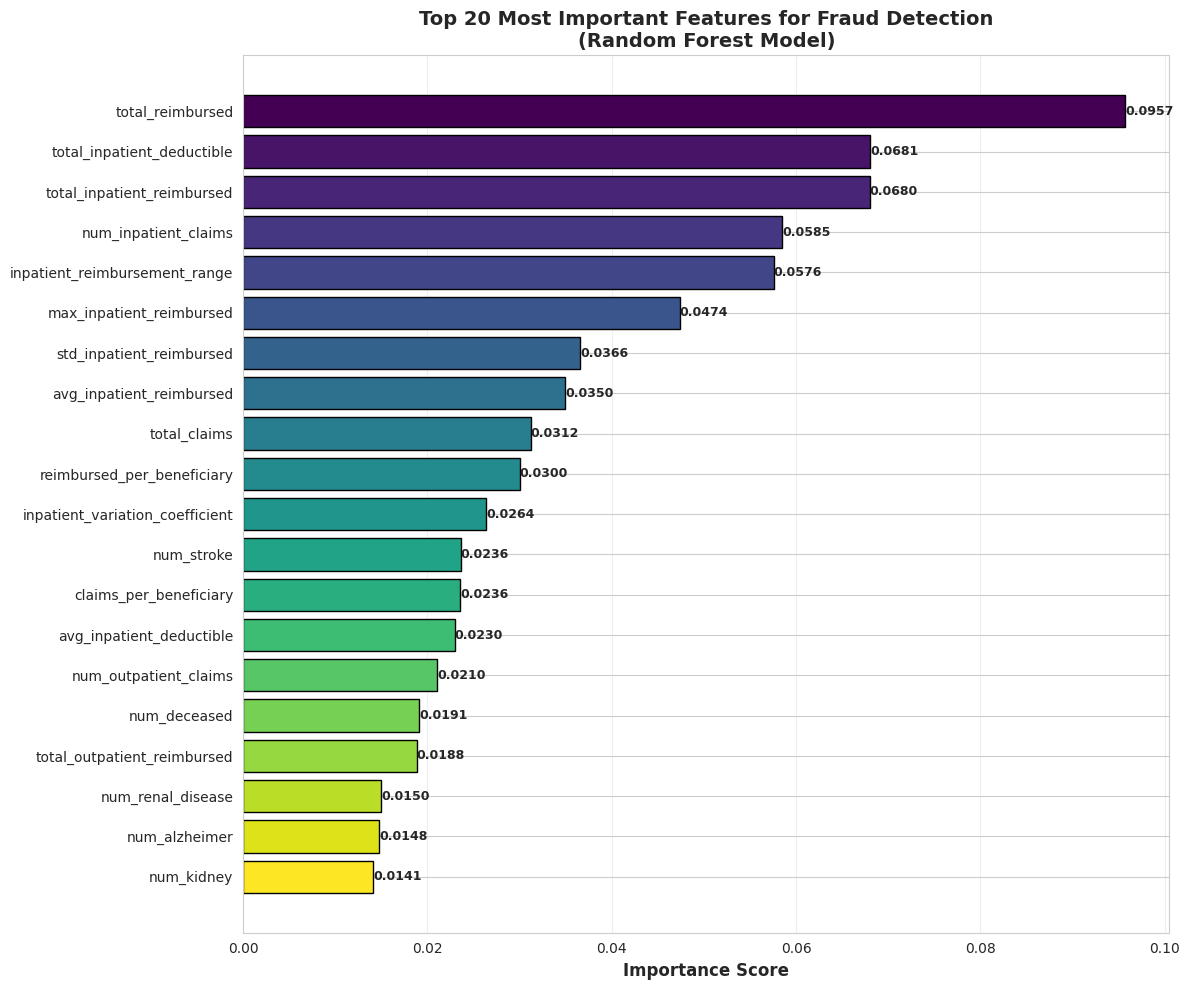


✅ Feature importance analysis complete!


In [14]:
# Feature Importance Analysis
print("="*80)
print("📊 FEATURE IMPORTANCE ANALYSIS")
print("="*80)

# Get feature importance from Random Forest (best for feature importance)
feature_importance = pd.DataFrame({
    'Feature': X.columns,
    'Importance': models['Random Forest'].feature_importances_
}).sort_values('Importance', ascending=False)

print("\nTop 20 Most Important Features:")
print(feature_importance.head(20).to_string(index=False))

# Visualize
plt.figure(figsize=(12, 10))
top_features = feature_importance.head(20)
colors = plt.cm.viridis(np.linspace(0, 1, len(top_features)))
bars = plt.barh(range(len(top_features)), top_features['Importance'], color=colors, edgecolor='black')

plt.yticks(range(len(top_features)), top_features['Feature'])
plt.xlabel('Importance Score', fontweight='bold', fontsize=12)
plt.title('Top 20 Most Important Features for Fraud Detection\n(Random Forest Model)',
          fontweight='bold', fontsize=14)
plt.gca().invert_yaxis()
plt.grid(axis='x', alpha=0.3)

# Add value labels
for i, (bar, val) in enumerate(zip(bars, top_features['Importance'])):
    plt.text(val, bar.get_y() + bar.get_height()/2, f'{val:.4f}',
             va='center', ha='left', fontsize=9, fontweight='bold')

plt.tight_layout()
plt.savefig('/content/drive/MyDrive/fraud_detection_project/results/feature_importance.png',
            dpi=300, bbox_inches='tight')
plt.show()

# Save to CSV
feature_importance.to_csv('/content/drive/MyDrive/fraud_detection_project/results/feature_importance.csv', index=False)

print("\n✅ Feature importance analysis complete!")

In [15]:
# Save all results
print("="*80)
print("💾 SAVING ALL RESULTS")
print("="*80)

# Save predictions
predictions_df = pd.DataFrame({
    'Actual': y_test.values,
    'LR_Pred': predictions['Logistic Regression'],
    'DT_Pred': predictions['Decision Tree'],
    'RF_Pred': predictions['Random Forest'],
    'XGB_Pred': predictions['XGBoost'],
    'SVM_Pred': predictions['SVM'],
    'LR_Prob': probabilities['Logistic Regression'],
    'RF_Prob': probabilities['Random Forest'],
    'XGB_Prob': probabilities['XGBoost']
})
predictions_df.to_csv('/content/drive/MyDrive/fraud_detection_project/results/predictions.csv', index=False)
print("✅ Predictions saved")

# Save comparison
comparison.to_csv('/content/drive/MyDrive/fraud_detection_project/results/model_comparison.csv')
print("✅ Model comparison saved")

# Create summary document
summary = f"""
NOTEBOOK 2: MODELING - SUMMARY REPORT
{'='*80}

DATE: {pd.Timestamp.now().strftime('%Y-%m-%d %H:%M:%S')}

MODELS TRAINED: 5
{'='*80}
1. Logistic Regression
2. Decision Tree
3. Random Forest
4. XGBoost (Gradient Boosting)
5. Support Vector Machine (SVM)

BEST MODEL: Logistic Regression
{'='*80}
ROC-AUC:   {results['Logistic Regression']['ROC-AUC']:.4f}
Precision: {results['Logistic Regression']['Precision']:.4f}
Recall:    {results['Logistic Regression']['Recall']:.4f}
F1-Score:  {results['Logistic Regression']['F1-Score']:.4f}

ALL MODEL RESULTS:
{'='*80}
{comparison.to_string()}

ERROR ANALYSIS:
{'='*80}
False Positives: {fp_count}
False Negatives: {fn_count}
Fraud Detection Rate: {fraud_detection_rate:.1f}%

BUSINESS IMPACT:
{'='*80}
Potential Savings: ${money_saved:,.0f}

FILES SAVED:
{'='*80}
✓ model_comparison.csv
✓ predictions.csv
✓ feature_importance.csv
✓ all_models_evaluation.png
✓ feature_importance.png

NOTEBOOK 2 COMPLETE!
"""

with open('/content/drive/MyDrive/fraud_detection_project/reports/notebook2_summary.txt', 'w') as f:
    f.write(summary)

print(summary)
print("\n✅ All results saved!")
print("\n🎉 NOTEBOOK 2 COMPLETE!")

💾 SAVING ALL RESULTS
✅ Predictions saved
✅ Model comparison saved

NOTEBOOK 2: MODELING - SUMMARY REPORT

DATE: 2025-11-25 17:36:42

MODELS TRAINED: 5
1. Logistic Regression
2. Decision Tree  
3. Random Forest
4. XGBoost (Gradient Boosting)
5. Support Vector Machine (SVM)

BEST MODEL: Logistic Regression
ROC-AUC:   0.9506
Precision: 0.4279
Recall:    0.8812
F1-Score:  0.5761

ALL MODEL RESULTS:
                     Accuracy  Precision    Recall  F1-Score   ROC-AUC
Logistic Regression  0.878928   0.427885  0.881188  0.576052  0.950586
Decision Tree        0.875231   0.409574  0.762376  0.532872  0.902282
Random Forest        0.916821   0.538462  0.762376  0.631148  0.949233
XGBoost              0.924214   0.574803  0.722772  0.640351  0.950091
SVM                  0.863216   0.397380  0.900990  0.551515  0.939877

ERROR ANALYSIS:
False Positives: 119
False Negatives: 12
Fraud Detection Rate: 88.1%

BUSINESS IMPACT:
Potential Savings: $59,920,792,079

FILES SAVED:
✓ model_comparison.csv
